# Remaining Useful Life (RUL) model comparison

This notebook trains and compares four regression models using `rul_prediction_dataset.csv`. It reports MAE, RMSE, and R² for each held-out battery and for pooled out-of-fold predictions.

## Evaluation design

Rows from the same battery are related, so a random row split would let a model learn from a battery that also appears in validation. Instead, **Leave-One-Battery-Out** cross-validation holds out each battery in turn. `battery_id` and `test_id` are excluded from predictors. Numeric missing values are imputed inside each fold's pipeline, preventing preprocessing leakage.

The dataset contains only three batteries, so these results are an informative comparison on this dataset, not a precise estimate of performance on all future batteries. A data check below confirms that this prepared target is exactly each battery's maximum observed `discharge_cycle` minus the current cycle. At inference, that maximum is not known in advance; models therefore estimate it from batteries seen during training. This limitation is important when interpreting these scores.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

RANDOM_STATE = 42
DATA_PATH = Path("rul_prediction_dataset.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Run this notebook from the project directory "
        "or update DATA_PATH to the prepared CSV location."
    )

df = pd.read_csv(DATA_PATH)
required_columns = {
    "battery_id", "discharge_cycle", "voltage_drop", "voltage_slope_v_per_s",
    "temperature_rise", "Re", "Rct", "RUL", "test_id",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if df["RUL"].isna().any() or df["battery_id"].isna().any():
    raise ValueError("RUL and battery_id must not contain missing values.")

print(f"Loaded {len(df):,} rows and {df['battery_id'].nunique()} batteries from {DATA_PATH.resolve()}")
display(df.head())

Loaded 331 rows and 3 batteries from C:\Users\prshi\OneDrive\Desktop\SOH-prediction-using-NASA-Dataset-master\SOH-prediction-using-NASA-Dataset-master\rul_prediction_dataset.csv


,battery_id,discharge_cycle,voltage_drop,voltage_slope_v_per_s,temperature_rise,Re,Rct,RUL,test_id
0,B0005,1,0.914322,-0.000206,14.652147,NaN,NaN,124,1
1,B0005,2,0.889528,-0.000205,14.335646,NaN,NaN,123,3
2,B0005,3,0.860736,-0.000200,14.084531,NaN,NaN,122,5
3,B0005,4,0.874279,-0.000205,14.108068,NaN,NaN,121,7
4,B0005,5,0.882802,-0.000208,14.140596,NaN,NaN,120,9


In [2]:
print("Rows and RUL range by battery:")
display(
    df.groupby("battery_id", as_index=False)
      .agg(rows=("RUL", "size"), cycle_min=("discharge_cycle", "min"),
           cycle_max=("discharge_cycle", "max"), RUL_min=("RUL", "min"), RUL_max=("RUL", "max"))
)
rul_from_observed_end = df.groupby("battery_id")["discharge_cycle"].transform("max") - df["discharge_cycle"]
target_matches_observed_end = np.array_equal(df["RUL"].to_numpy(), rul_from_observed_end.to_numpy())
print(f"RUL equals per-battery max(discharge_cycle) - discharge_cycle for every row: {target_matches_observed_end}")
print("Missing values in candidate predictors:")
display(df[["discharge_cycle", "voltage_drop", "voltage_slope_v_per_s", "temperature_rise", "Re", "Rct"]].isna().sum().rename("missing_count").to_frame())

FEATURES = [
    "discharge_cycle", "voltage_drop", "voltage_slope_v_per_s",
    "temperature_rise", "Re", "Rct",
]
TARGET = "RUL"
X = df[FEATURES].apply(pd.to_numeric, errors="raise")
y = pd.to_numeric(df[TARGET], errors="raise")
groups = df["battery_id"]
if groups.nunique() < 2:
    raise ValueError("At least two battery groups are required for grouped validation.")
if not np.isfinite(y.to_numpy(dtype=float)).all():
    raise ValueError("RUL must contain only finite numeric values.")

print(f"Features ({len(FEATURES)}): {FEATURES}")
print("Excluded from predictors: battery_id, test_id, and RUL.")

Rows and RUL range by battery:


,battery_id,rows,cycle_min,cycle_max,RUL_min,RUL_max
0,B0005,125,1,125,0,124
1,B0006,109,1,109,0,108
2,B0018,97,1,97,0,96


RUL equals per-battery max(discharge_cycle) - discharge_cycle for every row: True
Missing values in candidate predictors:


,missing_count
discharge_cycle,0
voltage_drop,0
voltage_slope_v_per_s,0
temperature_rise,0
Re,38
Rct,38


Features (6): ['discharge_cycle', 'voltage_drop', 'voltage_slope_v_per_s', 'temperature_rise', 'Re', 'Rct']
Excluded from predictors: battery_id, test_id, and RUL.


## Train and evaluate four models

Ridge Regression and RBF Support Vector Regression use standard scaling after median imputation. Random Forest and Histogram Gradient Boosting use median imputation without scaling. Each battery is predicted only by a model fitted on the other batteries.

In [3]:
models = {
    "Ridge": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0),
    ),
    "SVR (RBF)": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVR(kernel="rbf", C=10.0, epsilon=0.1),
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    ),
    "Hist. Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, random_state=RANDOM_STATE),
    ),
}

logo = LeaveOneGroupOut()
fold_rows = []
oof_predictions = {name: np.full(len(df), np.nan, dtype=float) for name in models}

for fold_number, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
    held_out_battery = groups.iloc[test_idx].unique()
    if len(held_out_battery) != 1:
        raise RuntimeError("Expected each validation fold to contain exactly one held-out battery.")
    battery = held_out_battery[0]
    for name, estimator in models.items():
        estimator.fit(X.iloc[train_idx], y.iloc[train_idx])
        predictions = estimator.predict(X.iloc[test_idx])
        oof_predictions[name][test_idx] = predictions
        fold_rows.append({
            "model": name,
            "held_out_battery": battery,
            "n_test": len(test_idx),
            "MAE": mean_absolute_error(y.iloc[test_idx], predictions),
            "RMSE": np.sqrt(mean_squared_error(y.iloc[test_idx], predictions)),
            "R2": r2_score(y.iloc[test_idx], predictions),
        })

if any(not np.isfinite(predictions).all() for predictions in oof_predictions.values()):
    raise RuntimeError("Some rows did not receive a finite out-of-fold prediction.")

fold_metrics = pd.DataFrame(fold_rows)
print(f"Completed {logo.get_n_splits(X, y, groups)} leave-one-battery-out folds for {len(models)} models.")

Completed 3 leave-one-battery-out folds for 4 models.


In [4]:
pooled_rows = []
for name, predictions in oof_predictions.items():
    pooled_rows.append({
        "model": name,
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions),
    })

pooled_metrics = pd.DataFrame(pooled_rows).sort_values("MAE").reset_index(drop=True)
print("Pooled out-of-fold metrics (all held-out batteries combined; lower MAE/RMSE is better, higher R² is better):")
display(pooled_metrics.round(3))
print("Metrics by held-out battery:")
display(fold_metrics.sort_values(["held_out_battery", "MAE"]).round(3))

best_model_name = pooled_metrics.loc[0, "model"]
print(f"Best model by pooled MAE: {best_model_name} (MAE = {pooled_metrics.loc[0, 'MAE']:.3f} RUL cycles)")

Pooled out-of-fold metrics (all held-out batteries combined; lower MAE/RMSE is better, higher R² is better):


,model,MAE,RMSE,R2
0,Hist. Gradient Boosting,14.139,15.673,0.773
1,Random Forest,14.990,16.457,0.749
2,Ridge,17.262,19.190,0.659
3,SVR (RBF),20.569,25.358,0.405


Metrics by held-out battery:


,model,held_out_battery,n_test,MAE,RMSE,R2
3,Hist. Gradient Boosting,B0005,125,15.135,16.255,0.797
2,Random Forest,B0005,125,16.391,17.590,0.762
1,SVR (RBF),B0005,125,22.951,26.646,0.455
0,Ridge,B0005,125,24.732,24.912,0.523
7,Hist. Gradient Boosting,B0006,109,8.717,9.854,0.902
6,Random Forest,B0006,109,10.420,11.158,0.874
4,Ridge,B0006,109,10.755,14.265,0.794
5,SVR (RBF),B0006,109,17.536,23.890,0.423
8,Ridge,B0018,97,14.949,15.106,0.709
10,Random Forest,B0018,97,18.318,19.634,0.508


Best model by pooled MAE: Hist. Gradient Boosting (MAE = 14.139 RUL cycles)


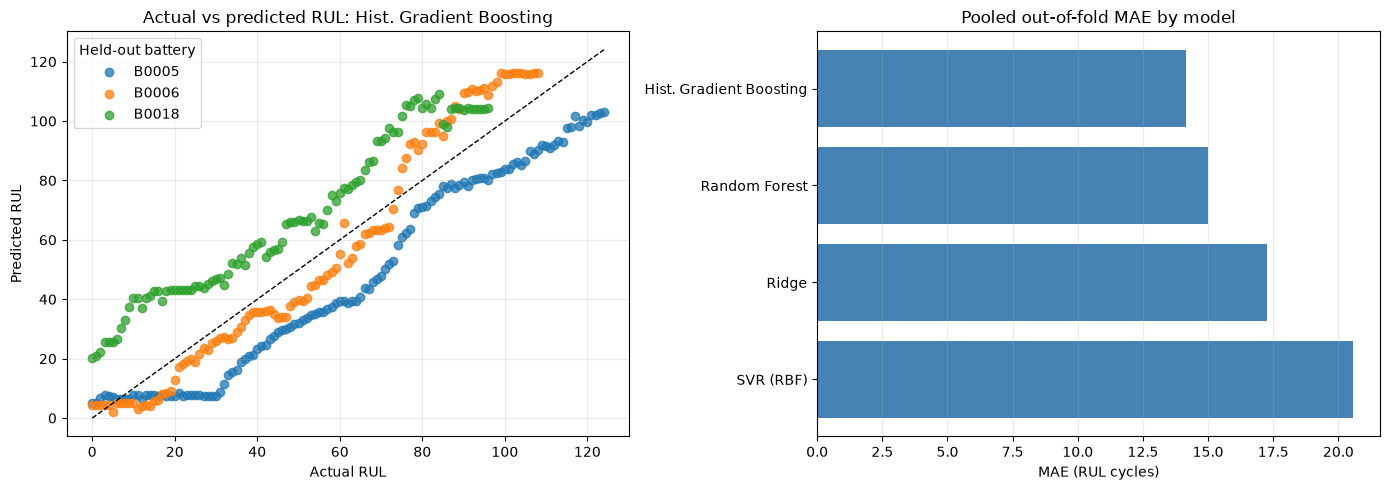

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

best_predictions = oof_predictions[best_model_name]
for battery in groups.unique():
    mask = groups.to_numpy() == battery
    axes[0].scatter(y.to_numpy()[mask], best_predictions[mask], alpha=0.75, label=battery)
low = min(float(y.min()), float(best_predictions.min()))
high = max(float(y.max()), float(best_predictions.max()))
axes[0].plot([low, high], [low, high], "k--", linewidth=1)
axes[0].set(title=f"Actual vs predicted RUL: {best_model_name}", xlabel="Actual RUL", ylabel="Predicted RUL")
axes[0].legend(title="Held-out battery")
axes[0].grid(alpha=0.25)

plot_metrics = pooled_metrics.sort_values("MAE", ascending=True)
axes[1].barh(plot_metrics["model"], plot_metrics["MAE"], color="steelblue")
axes[1].invert_yaxis()
axes[1].set(title="Pooled out-of-fold MAE by model", xlabel="MAE (RUL cycles)", ylabel="")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## Interpretation and limitations

- Use the pooled out-of-fold table to compare average error, and the per-battery table to see whether results vary by held-out battery.
- The selected model is the one with the lowest pooled MAE; lower MAE and RMSE indicate smaller errors in RUL cycles. R² can be negative when predictions are worse than predicting the evaluation-set mean.
- Only three batteries are available, so leave-one-battery-out validation has just three folds. More independent batteries are needed for a reliable estimate of deployment performance.
- In this CSV, RUL is exactly `max(discharge_cycle) - discharge_cycle` within each battery. The maximum cycle is only known retrospectively, so the model estimates that battery-specific endpoint from training batteries; it cannot know the true endpoint in advance.
- This notebook deliberately does not use `test_id` or `battery_id`; it evaluates whether features generalize across unseen battery groups, rather than relying on identifiers or knowing the held-out battery's endpoint.